# WGAN on MNIST: a GAN whose loss finally means something

**The question:** a classic GAN's discriminator loss is famously useless as a progress bar: it bounces around even while the pictures improve. The **Wasserstein GAN (WGAN)** replaces the yes/no discriminator with a *critic* that scores images, and claims the critic's score gap between real and fake images is a **meaningful, falling number** that tracks image quality. The price is a crude trick: squeezing every critic weight into a tiny range ("weight clipping"). *Does the WGAN's loss really track quality, how touchy is the clipping bound, and does it beat the classic GAN at the same budget?* Quality is judged by an independent referee network, not by the loss.

**How this notebook works.** Each section starts with a plain-English explanation, then the code, then a "how to read this" note.

1. The analogy
2. Setup
3. The referee: a way to judge generated digits
4. Hypotheses and why we chose each test
5. The two training recipes
6. H1: does the WGAN loss track quality?
7. H2: how touchy is the clipping bound?
8. H3: does the WGAN beat the classic GAN?
9. Takeaways
10. Limitations

**Run it:** `uv run jupyter lab GAN/wgan/wgan.ipynb`, or *Run All* in any Jupyter. MNIST (about 12 MB) downloads itself on the first run. It uses a GPU if present and takes about 40 minutes on one.

## 1. 💡 The simple analogy

Picture a **forger and a judge** again, but with two different judges.

- The **classic judge** only says "real" or "fake". Once the forger is decent, the judge is often confidently right or confidently wrong, and the verdicts say little about *how close* the fakes are.
- The **WGAN judge (critic)** gives every painting a **score**, and the forger is trained to raise the fakes' scores toward the real ones. The *gap* between the average real score and the average fake score says **how far apart** the two piles still are, so it shrinks as the forger improves.
- For the scores to be honest, the judge must not be allowed to shout: his scores may only change slowly from one painting to a similar one. The original WGAN enforces this the bluntest way possible: it **clamps every number inside the judge's brain** into a narrow band (weight clipping). Too narrow and the judge cannot tell anything apart; too wide and the scores stop being honest.

## 2. Setup

*What:* imports and named constants. *Why:* one place for numbers like the seed, the image size and the training budget keeps the notebook reproducible and avoids "magic numbers". **We use 32 x 32 images** (MNIST digits padded out from 28 pixels) where the legacy scripts used 64 x 64: the smaller size is far cheaper to train on one small GPU and loses nothing important for digits. Each run is **5,000 generator updates** with batches of 64.

In [1]:
import contextlib
import io
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn.functional as F
from scipy import stats
from torch import nn
from torchvision import datasets

DATA_DIR = Path("data")
OUT_DIR = Path("outputs")
SEED = 365
IMAGE_SIZE = 32  # MNIST digits are padded out from 28 to 32 pixels (the legacy scripts used 64)
Z_DIM = 100
FEATURES = 32  # width multiplier of the generator and the critic
N_EVAL = 10_000  # generated images used for the final scores
N_BOOTSTRAP = 2_000
BATCH = 64
GEN_STEPS = 5_000  # generator updates per training run
TRACK_EVERY = 250
CRITIC_STEPS = 5  # critic updates per generator update (the WGAN paper's value)
N_SEEDS = 3
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
TEAL, ORANGE, NAVY, GREY, PURPLE = "#2a9d8f", "#e76f51", "#264653", "#b8bcc2", "#7b5ea7"

torch.backends.cudnn.deterministic = True  # same seed, same result, even on the GPU
torch.backends.cudnn.benchmark = False
sns.set_theme(style="whitegrid", context="notebook")
OUT_DIR.mkdir(exist_ok=True)
DATA_DIR.mkdir(exist_ok=True)
rng = np.random.default_rng(SEED)


def fmt_p(p: float) -> str:
    """Formats a p-value, showing values below floating-point precision honestly.

    Args:
        p: The p-value.

    Returns:
        A short string such as ``3.2e-08`` or ``< 1e-300``.
    """
    return "< 1e-300" if float(p) < 1e-300 else f"{float(p):.1e}"

## 3. The referee: a way to judge generated digits

*What:* a GAN has no accuracy to report, so we build an **independent referee**: a small digit classifier trained only on real MNIST digits. It gives us three scores for any set of generated digits:

- **Fréchet distance (FD):** compare the *average and spread* of the referee's internal description of the generated digits with those of real test digits. Zero means identical; lower is better.
- **Inception-style score:** high only if the referee is **sure** about each image *and* all ten digits appear (a perfect score is 10).
- **Confident share:** the share of images the referee is more than 90% sure about.

To know what "good" looks like, we first score **real digits against real digits**: the floor no generator can beat.

In [2]:
def load_mnist() -> tuple[torch.Tensor, torch.Tensor, torch.Tensor, torch.Tensor]:
    """Loads MNIST as uint8 tensors (N, 28, 28) with labels, on the compute device.

    Returns:
        Training images and labels, then test images and labels.

    Raises:
        ValueError: If the dataset does not have the expected shape.
    """
    with contextlib.redirect_stderr(io.StringIO()):  # hide the download progress bars
        train = datasets.MNIST(DATA_DIR, train=True, download=True)
        test = datasets.MNIST(DATA_DIR, train=False, download=True)
    if tuple(train.data.shape) != (60_000, 28, 28) or tuple(test.data.shape) != (10_000, 28, 28):
        raise ValueError("Unexpected MNIST shape")
    return (
        train.data.to(DEVICE),
        train.targets.to(DEVICE),
        test.data.to(DEVICE),
        test.targets.to(DEVICE),
    )


def to_gan_scale(images: torch.Tensor) -> torch.Tensor:
    """Turns uint8 digits (N, 28, 28) into float images (N, 1, 32, 32) with values in [-1, 1]."""
    x = images.float().div(127.5).sub(1).unsqueeze(1)
    return F.interpolate(x, size=(IMAGE_SIZE, IMAGE_SIZE), mode="bilinear", align_corners=False)


def to_referee_scale(images: torch.Tensor) -> torch.Tensor:
    """Turns GAN-scale images (N, 1, 32, 32) back to (N, 1, 28, 28) in [0, 1] for the referee."""
    small = F.interpolate((images + 1) / 2, size=(28, 28), mode="area")
    return small.clamp(0, 1)


class Referee(nn.Module):
    """A small digit classifier (trained on real digits) used to judge generated images."""

    def __init__(self) -> None:
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
        )
        self.head = nn.Linear(128, 10)

    def forward(self, x: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
        """Returns class scores and the 128-number feature vector."""
        features = self.conv(x)
        return self.head(features), features


train_x, train_y, test_x, test_y = load_mnist()
torch.manual_seed(SEED)
referee = Referee().to(DEVICE)
optimizer = torch.optim.Adam(referee.parameters(), lr=1e-3)
for _ in range(3):
    order = torch.randperm(len(train_x), device=DEVICE)
    for start in range(0, len(order), 128):
        pick = order[start : start + 128]
        scores, _ = referee(train_x[pick].float().div(255).unsqueeze(1))
        loss = F.cross_entropy(scores, train_y[pick])
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
referee.eval()


def referee_outputs(images01: torch.Tensor) -> tuple[np.ndarray, np.ndarray]:
    """Class probabilities and features for images in [0, 1] of shape (N, 1, 28, 28).

    Args:
        images01: Images scaled to [0, 1].

    Returns:
        Probabilities (N, 10) and features (N, 128) as NumPy arrays.
    """
    probs, feats = [], []
    with torch.no_grad():
        for start in range(0, len(images01), 2000):
            scores, f = referee(images01[start : start + 2000])
            probs.append(F.softmax(scores, dim=1).cpu().numpy())
            feats.append(f.cpu().numpy())
    return np.concatenate(probs), np.concatenate(feats).astype(np.float64)


test_probs, test_feats = referee_outputs(test_x.float().div(255).unsqueeze(1))
train_probs, train_feats = referee_outputs(train_x.float().div(255).unsqueeze(1))
REAL_MU, REAL_COV = test_feats.mean(0), np.cov(test_feats, rowvar=False)
real_share = np.bincount(test_y.cpu().numpy(), minlength=10) / len(test_y)
print(
    f"Referee accuracy on the real test digits: "
    f"{(test_probs.argmax(1) == test_y.cpu().numpy()).mean():.2%}"
)
print(
    f"Real digits per class in the test set: min {real_share.min():.1%}, max {real_share.max():.1%}"
)


def frechet_distance(
    feats: np.ndarray, mu_ref: np.ndarray = REAL_MU, cov_ref: np.ndarray = REAL_COV
) -> float:
    """Frechet distance between two clouds of referee features (lower = more alike).

    It compares the mean and spread of the features of some images with those of the real test
    digits; it is the digit-sized cousin of the FID used for photographs.

    Args:
        feats: Features of the images to judge, shape (N, 128).
        mu_ref: Mean of the reference features.
        cov_ref: Covariance of the reference features.

    Returns:
        The Frechet distance.
    """
    mu, cov = feats.mean(0), np.cov(feats, rowvar=False)
    # trace of the matrix square root of cov @ cov_ref = sum of square roots of its eigenvalues,
    # which are real and non-negative because both matrices are covariance matrices
    eigenvalues = np.linalg.eigvals(cov @ cov_ref).real.clip(min=0)
    return float(
        np.sum((mu - mu_ref) ** 2) + np.trace(cov + cov_ref) - 2 * np.sqrt(eigenvalues).sum()
    )


def inception_style_score(probs: np.ndarray) -> float:
    """exp(average KL divergence between each image's class guess and the overall class mix).

    High when every image is clearly one digit AND all ten digits appear. A perfect score is 10.

    Args:
        probs: Referee class probabilities, shape (N, 10).

    Returns:
        The score.
    """
    marginal = probs.mean(0, keepdims=True)
    kl = (probs * (np.log(probs + 1e-12) - np.log(marginal + 1e-12))).sum(1)
    return float(np.exp(kl.mean()))


@torch.no_grad()
def judge(generator: nn.Module, n: int = N_EVAL, seed: int = 0) -> dict:
    """Scores a generator: Frechet distance, Inception-style score, confidence and class mix.

    Args:
        generator: The generator to judge (it is run in training mode, so batch normalisation
            uses the statistics of each batch of 1,000 images, as when it was trained).
        n: Number of images to generate.
        seed: Seed for the random noise, so every generator sees the same noise.

    Returns:
        A dict with ``fd``, ``is``, ``confident`` (share of images the referee is more than 90%
        sure about), ``tvd`` (total variation distance of the class mix from the real one) and
        ``share`` (the class mix).
    """
    generator.train()
    gen_cuda = torch.Generator(device=DEVICE).manual_seed(seed)
    images = torch.cat(
        [
            generator(torch.randn(1000, Z_DIM, 1, 1, device=DEVICE, generator=gen_cuda))
            for _ in range(n // 1000)
        ]
    )
    probs, feats = referee_outputs(to_referee_scale(images))
    share = np.bincount(probs.argmax(1), minlength=10) / len(probs)
    return {
        "fd": frechet_distance(feats),
        "is": inception_style_score(probs),
        "confident": float((probs.max(1) > 0.9).mean()),
        "tvd": float(0.5 * np.abs(share - real_share).sum()),
        "share": share,
    }


floor_rows = []
for i in range(5):
    sub = np.random.default_rng(i).choice(len(train_feats), N_EVAL, replace=False)
    floor_rows.append(
        {
            "fd": frechet_distance(train_feats[sub]),
            "is": inception_style_score(train_probs[sub]),
            "confident": float((train_probs[sub].max(1) > 0.9).mean()),
        }
    )
floor = pd.DataFrame(floor_rows)
print(
    f"Real digits judged the same way (10,000 real training digits against the real test "
    f"digits, 5 draws):\n  Frechet distance {floor['fd'].mean():.2f} "
    f"(range {floor['fd'].min():.2f} to {floor['fd'].max():.2f}), Inception-style score "
    f"{floor['is'].mean():.2f}, referee confident on {floor['confident'].mean():.1%}"
)

Referee accuracy on the real test digits: 98.92%
Real digits per class in the test set: min 8.9%, max 11.3%
Real digits judged the same way (10,000 real training digits against the real test digits, 5 draws):
  Frechet distance 1.89 (range 1.78 to 2.01), Inception-style score 9.59, referee confident on 96.6%


**How to read this:**

- **The referee is accurate:** it reads **98.92%** of the real test digits correctly.
- **The real-digit floor:** real training digits scored against the test digits give a Fréchet distance of **1.89** (range 1.78 to 2.01 over five draws), an Inception-style score of **9.59** (out of 10) and a referee that is confident on **96.6%** of images.
- **Real test digits are not perfectly balanced:** the commonest digit makes up **11.3%** and the rarest **8.9%**.

## 4. Hypotheses and why we chose each test

| # | Question | H₀ (nothing interesting) | Hₐ | Test |
|---|---|---|---|---|
| H1 | Does the WGAN's own loss signal track sample quality better than the classic GAN's? | No relationship between a run's loss signal and its Fréchet distance | A strong relationship for the WGAN only | Spearman rank correlation over 20 checkpoints per run, 3 seeds each; pooled test |
| H2 | Does the clipping bound matter? | Same quality at clip 0.001, 0.01 and 0.1 | Differs | Kruskal-Wallis on the Fréchet distance, 3 seeds per bound; share of critic weights stuck at the bound |
| H3 | Does the WGAN beat the classic GAN at this budget? | Same Fréchet distance | Differs | Mann-Whitney U, 3 seeds against 3 |

*Why these tests?* The loss and the Fréchet distance move together if the loss is a good progress bar, but not necessarily in a straight line, so we use the **rank-based Spearman correlation**. With three seeds per setting, only rank-based tests are safe, and we report the individual runs.

## 5. The two training recipes

*What:* two recipes with the same generator (noise of 100 numbers → three transposed-convolution blocks → a 32 x 32 image).

- **Classic GAN:** the discriminator ends in a 0-to-1 probability and uses batch norm; **binary cross-entropy**; **Adam** with learning rate 0.0002 and momentum 0.5; one discriminator update per generator update.
- **WGAN:** the critic ends in an unbounded score and uses instance norm (batch norm would mix the images in a batch); the critic maximises *average score of real minus average score of fake*; **RMSprop** with learning rate 0.00005; **5 critic updates per generator update**, and after every critic update all critic weights are **clipped to [-0.01, 0.01]**.
- Every 250 generator updates we record the run's own loss signal (the discriminator loss, or the critic's real-minus-fake estimate) and the Fréchet distance of 5,000 forged digits.

> **Problems in the legacy scripts this replaces:** training only wrote sample grids to TensorBoard with **no measurement of quality**, so the paper's claims were never checked.

In [3]:
class Generator(nn.Module):
    """DCGAN generator: noise (N, 100, 1, 1) -> image (N, 1, 32, 32) with values in [-1, 1].

    Args:
        features: Width multiplier (the legacy scripts use 64).
    """

    def __init__(self, features: int = FEATURES) -> None:
        super().__init__()

        def block(c_in: int, c_out: int, k: int, s: int, p: int) -> nn.Sequential:
            return nn.Sequential(
                nn.ConvTranspose2d(c_in, c_out, k, s, p, bias=False),
                nn.BatchNorm2d(c_out),
                nn.ReLU(),
            )

        self.net = nn.Sequential(
            block(Z_DIM, features * 8, 4, 1, 0),  # 4 x 4
            block(features * 8, features * 4, 4, 2, 1),  # 8 x 8
            block(features * 4, features * 2, 4, 2, 1),  # 16 x 16
            nn.ConvTranspose2d(features * 2, 1, 4, 2, 1),  # 32 x 32
            nn.Tanh(),
        )

    def forward(self, z: torch.Tensor) -> torch.Tensor:
        """Turns noise into images."""
        return self.net(z)


def init_weights(model: nn.Module) -> None:
    """Draws every convolution and normalisation weight from N(0, 0.02), as the DCGAN paper does."""
    for m in model.modules():
        if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d, nn.BatchNorm2d)):
            nn.init.normal_(m.weight.data, 0.0, 0.02)

In [4]:
class Critic(nn.Module):
    """The discriminator / critic: image (N, 1, 32, 32) -> one score per image.

    Args:
        features: Width multiplier.
        norm: ``"batch"``, ``"instance"`` or ``"none"`` normalisation between layers.
        sigmoid: Squash the score to (0, 1), as a standard GAN discriminator does.
    """

    def __init__(
        self, features: int = FEATURES, norm: str = "batch", sigmoid: bool = False
    ) -> None:
        super().__init__()

        def make_norm(c: int) -> nn.Module:
            if norm == "batch":
                return nn.BatchNorm2d(c)
            if norm == "instance":
                return nn.InstanceNorm2d(c, affine=True)
            return nn.Identity()

        def block(c_in: int, c_out: int) -> nn.Sequential:
            return nn.Sequential(
                nn.Conv2d(c_in, c_out, 4, 2, 1, bias=False), make_norm(c_out), nn.LeakyReLU(0.2)
            )

        layers: list[nn.Module] = [
            nn.Conv2d(1, features, 4, 2, 1),
            nn.LeakyReLU(0.2),  # 16 x 16
            block(features, features * 2),  # 8 x 8
            block(features * 2, features * 4),  # 4 x 4
            nn.Conv2d(features * 4, 1, 4, 1, 0),
        ]  # 1 x 1
        if sigmoid:
            layers.append(nn.Sigmoid())
        self.net = nn.Sequential(*layers)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """One score per image."""
        return self.net(x).reshape(-1)

In [5]:
def real_batches(batch: int, seed: int):
    """Endless stream of random batches of real digits at GAN scale.

    Args:
        batch: Batch size.
        seed: Seed for the shuffling.

    Yields:
        Tensors of shape (batch, 1, 32, 32).
    """
    gen_cuda = torch.Generator(device=DEVICE).manual_seed(seed)
    while True:
        order = torch.randperm(len(train_x), device=DEVICE, generator=gen_cuda)
        for start in range(0, len(order) - batch + 1, batch):
            yield to_gan_scale(train_x[order[start : start + batch]])


def show_grid(generator: nn.Module, ax: plt.Axes, seed: int = 123, n: int = 64) -> None:
    """Draws an 8 x 8 grid of generated digits on an axis.

    Args:
        generator: The generator.
        ax: The axis to draw on.
        seed: Seed for the noise.
        n: Number of images (a square number).
    """
    side = int(np.sqrt(n))
    with torch.no_grad():
        gen_cuda = torch.Generator(device=DEVICE).manual_seed(seed)
        images = generator(torch.randn(n, Z_DIM, 1, 1, device=DEVICE, generator=gen_cuda))
    grid = images.cpu().numpy()[:, 0].reshape(side, side, IMAGE_SIZE, IMAGE_SIZE)
    ax.imshow(
        grid.transpose(0, 2, 1, 3).reshape(side * IMAGE_SIZE, side * IMAGE_SIZE),
        cmap="gray",
        vmin=-1,
        vmax=1,
    )
    ax.axis("off")

In [6]:
def train_bce(seed: int, steps: int = GEN_STEPS) -> tuple[nn.Module, pd.DataFrame]:
    """The classic GAN: a discriminator with binary cross-entropy, one update each per step.

    Args:
        seed: Seed for the weights, batches and noise.
        steps: Number of generator updates.

    Returns:
        The generator and a table (one row per checkpoint) with the discriminator loss and the
        Frechet distance of 5,000 generated digits.
    """
    torch.manual_seed(seed)
    gen, disc = Generator().to(DEVICE), Critic(FEATURES, "batch", sigmoid=True).to(DEVICE)
    init_weights(gen)
    init_weights(disc)
    opt_gen = torch.optim.Adam(gen.parameters(), lr=2e-4, betas=(0.5, 0.999))
    opt_disc = torch.optim.Adam(disc.parameters(), lr=2e-4, betas=(0.5, 0.999))
    stream = real_batches(BATCH, seed)
    ones, zeros = torch.ones(BATCH, device=DEVICE), torch.zeros(BATCH, device=DEVICE)
    rows, window = [], []
    for step in range(1, steps + 1):
        real = next(stream)
        fake = gen(torch.randn(BATCH, Z_DIM, 1, 1, device=DEVICE))
        d_real, d_fake = disc(real), disc(fake.detach())
        loss_disc = (
            F.binary_cross_entropy(d_real, ones) + F.binary_cross_entropy(d_fake, zeros)
        ) / 2
        opt_disc.zero_grad()
        loss_disc.backward()
        opt_disc.step()
        loss_gen = F.binary_cross_entropy(disc(fake), ones)
        opt_gen.zero_grad()
        loss_gen.backward()
        opt_gen.step()
        window.append(loss_disc.item())
        if step % TRACK_EVERY == 0:
            rows.append(
                {
                    "step": step,
                    "signal": float(np.mean(window)),
                    "fd": judge(gen, 5_000, seed=1)["fd"],
                }
            )
            window = []
    return gen, pd.DataFrame(rows)


def train_wgan(
    seed: int, clip: float = 0.01, steps: int = GEN_STEPS
) -> tuple[nn.Module, nn.Module, pd.DataFrame]:
    """The Wasserstein GAN with weight clipping.

    Each generator update is preceded by ``CRITIC_STEPS`` critic updates on fresh real and fake
    batches. After every critic update all critic weights are squeezed into [-clip, clip].

    Args:
        seed: Seed for the weights, batches and noise.
        clip: The clipping bound.
        steps: Number of generator updates.

    Returns:
        The generator, the critic, and a table (one row per checkpoint) with the critic's
        Wasserstein estimate (average score of real minus fake) and the Frechet distance.
    """
    torch.manual_seed(seed)
    gen, critic = Generator().to(DEVICE), Critic(FEATURES, "instance").to(DEVICE)
    init_weights(gen)
    init_weights(critic)
    opt_gen = torch.optim.RMSprop(gen.parameters(), lr=5e-5)
    opt_critic = torch.optim.RMSprop(critic.parameters(), lr=5e-5)
    stream = real_batches(BATCH, seed)
    rows, window = [], []
    for step in range(1, steps + 1):
        for _ in range(CRITIC_STEPS):
            real = next(stream)
            with torch.no_grad():
                fake = gen(torch.randn(BATCH, Z_DIM, 1, 1, device=DEVICE))
            estimate = critic(real).mean() - critic(fake).mean()
            opt_critic.zero_grad()
            (-estimate).backward()
            opt_critic.step()
            for p in critic.parameters():
                p.data.clamp_(-clip, clip)
        fake = gen(torch.randn(BATCH, Z_DIM, 1, 1, device=DEVICE))
        loss_gen = -critic(fake).mean()
        opt_gen.zero_grad()
        loss_gen.backward()
        opt_gen.step()
        window.append(estimate.item())
        if step % TRACK_EVERY == 0:
            rows.append(
                {
                    "step": step,
                    "signal": float(np.mean(window)),
                    "fd": judge(gen, 5_000, seed=1)["fd"],
                }
            )
            window = []
    return gen, critic, pd.DataFrame(rows)

**How to read this:**

- **A fair-budget warning:** per generator update, the WGAN critic sees 5 batches of real digits and the classic discriminator sees 1. After 5,000 updates the WGAN has therefore looked at about **1.6 million** real digits (about 27 passes over MNIST) and the classic GAN at **320,000** (about 5 passes). This favours the WGAN, so a result in the classic GAN's favour is the more striking.

## 6. H1: does the WGAN loss track quality?

*What:* train the classic GAN and the WGAN (clip 0.01) three times each (seeds 0, 1 and 2). For every run we have 20 checkpoints, each with the run's own loss signal and the Fréchet distance of its forged digits. We ask: **does the loss signal rank the checkpoints the way the referee does?** (Spearman correlation per run, and pooled over all 60 checkpoints per recipe.) *Why:* if the loss is a good progress bar, you could stop training, compare settings or spot trouble from the loss alone, with no referee.

In [7]:
bce_runs = [train_bce(seed) for seed in range(N_SEEDS)]
wgan_runs = [train_wgan(seed) for seed in range(N_SEEDS)]
corr_rows = []
for seed in range(N_SEEDS):
    bce_h, wgan_h = bce_runs[seed][1], wgan_runs[seed][2]
    corr_rows.append(
        {
            "seed": seed,
            "WGAN critic estimate vs FD": stats.spearmanr(wgan_h["signal"], wgan_h["fd"]).statistic,
            "BCE discriminator loss vs FD": stats.spearmanr(bce_h["signal"], bce_h["fd"]).statistic,
        }
    )
corr = pd.DataFrame(corr_rows).set_index("seed")
print(
    f"Spearman correlation, over {len(wgan_runs[0][2])} checkpoints per run, between a "
    "run's own loss signal and the Frechet distance to real digits:"
)
print(corr.round(2).to_string())
print(f"mean: WGAN {corr.iloc[:, 0].mean():+.2f}, BCE {corr.iloc[:, 1].mean():+.2f}")
all_w = pd.concat([r[2] for r in wgan_runs])
rho = stats.spearmanr(all_w["signal"], all_w["fd"])
print(
    f"All WGAN checkpoints pooled ({len(all_w)}): rho = {rho.statistic:+.2f}, "
    f"p = {fmt_p(rho.pvalue)}"
)
all_b = pd.concat([r[1] for r in bce_runs])
rho_b = stats.spearmanr(all_b["signal"], all_b["fd"])
print(
    f"All BCE checkpoints pooled ({len(all_b)}): rho = {rho_b.statistic:+.2f}, "
    f"p = {fmt_p(rho_b.pvalue)}"
)

Spearman correlation, over 20 checkpoints per run, between a run's own loss signal and the Frechet distance to real digits:
      WGAN critic estimate vs FD  BCE discriminator loss vs FD
seed                                                          
0                           0.98                          0.60
1                           0.98                          0.65
2                           0.97                          0.63
mean: WGAN +0.98, BCE +0.63
All WGAN checkpoints pooled (60): rho = +0.97, p = 1.8e-38
All BCE checkpoints pooled (60): rho = +0.54, p = 9.1e-06


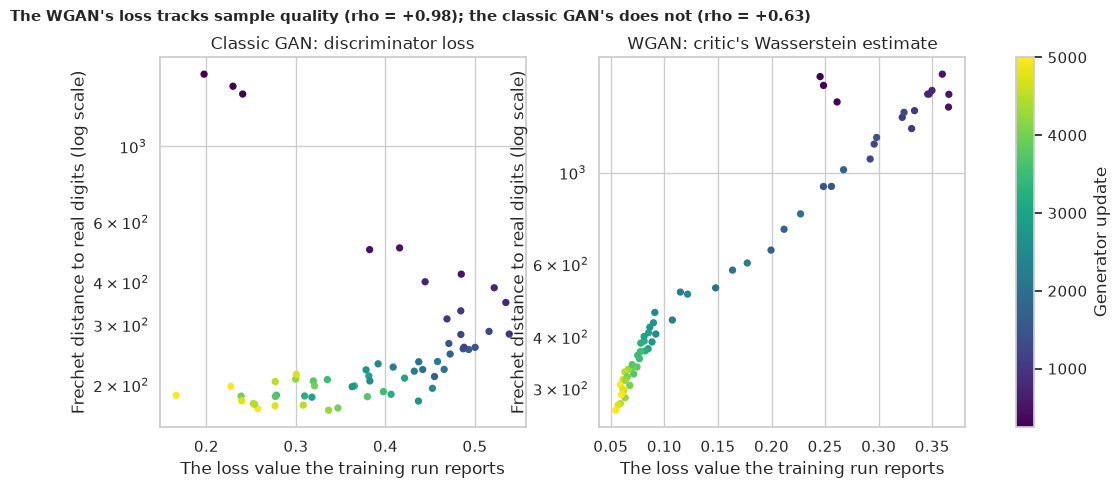

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=False)
for ax, runs, idx, title in [
    (axes[0], bce_runs, 1, "Classic GAN: discriminator loss"),
    (axes[1], wgan_runs, 2, "WGAN: critic's Wasserstein estimate"),
]:
    for _, *rest in [(None,) + (r[idx],) for r in runs]:
        history = rest[0]
        sc = ax.scatter(history["signal"], history["fd"], c=history["step"], cmap="viridis", s=18)
    ax.set_yscale("log")
    ax.set_xlabel("The loss value the training run reports")
    ax.set_ylabel("Frechet distance to real digits (log scale)")
    ax.set_title(title)
fig.colorbar(sc, ax=axes, label="Generator update")
mean_w, mean_b = corr.iloc[:, 0].mean(), corr.iloc[:, 1].mean()
fig.suptitle(
    f"The WGAN's loss tracks sample quality (rho = {mean_w:+.2f}); the classic GAN's "
    f"does not (rho = {mean_b:+.2f})",
    x=0.01,
    ha="left",
    fontweight="bold",
    fontsize=11,
)
fig.savefig(OUT_DIR / "01_loss_vs_quality.png", dpi=150, bbox_inches="tight")
plt.show()

**How to read this:**

- **The WGAN's critic estimate is an excellent progress bar:** its Spearman correlation with the Fréchet distance is **+0.98, +0.98 and +0.97** in the three runs (pooled over 60 checkpoints: **+0.97**, p = 2e-38). As the critic's real-minus-fake gap shrinks, the forged digits get closer to real ones.
- **The classic discriminator loss is a much weaker one:** **+0.60, +0.65 and +0.63** per run (pooled **+0.54**, p = 9e-6). It is correlated, but much less reliably.
- **We reject H₀ for both**, but the difference between the recipes is the point: the WGAN claim that "the loss means something" holds in our runs.
- Note the caveat the figure shows: the correlation is measured **within** a run over time. Across different clipping bounds (next section) the critic's number cannot be compared at all.

## 7. H2: how touchy is the clipping bound?

*What:* repeat the WGAN with a clip of **0.001**, **0.01** (the original paper's value) and **0.1**, three seeds each. We compare the Fréchet distance across the three bounds with a Kruskal-Wallis test and measure the **share of critic weights sitting at the bound** at the end of training. *Why:* clipping is the WGAN's least elegant part. If the critic's weights pile up at the bound, the critic is being held back by the clip rather than learning freely.

In [9]:
CLIPS = [0.001, 0.01, 0.1]
clip_rows, saturation_rows, clip_gens = [], [], {}
for clip in CLIPS:
    for seed in range(N_SEEDS):
        if clip == 0.01:
            gen, critic, _ = wgan_runs[seed]
        else:
            gen, critic, _ = train_wgan(seed, clip=clip)
        score = judge(gen)
        clip_rows.append(
            {
                "clip": clip,
                "seed": seed,
                "fd": score["fd"],
                "is": score["is"],
                "confident": score["confident"],
                "tvd": score["tvd"],
            }
        )
        weights = torch.cat([p.data.flatten() for p in critic.parameters() if p.dim() > 1])
        saturation_rows.append(
            {
                "clip": clip,
                "seed": seed,
                "at_bound": float((weights.abs() >= 0.99 * clip).float().mean()),
            }
        )
        if seed == 0:
            clip_gens[clip] = gen
clips = pd.DataFrame(clip_rows)
sat = pd.DataFrame(saturation_rows)
summary = clips.groupby("clip")[["fd", "is", "confident", "tvd"]].agg(["mean", "min", "max"])
print(summary.round(2).to_string())
print("\nShare of the critic's weights sitting at the clipping bound (within 1%):")
print((sat.groupby("clip")["at_bound"].agg(["mean", "min", "max"]) * 100).round(1).to_string())
groups = [g["fd"].to_numpy() for _, g in clips.groupby("clip")]
kw = stats.kruskal(*groups)
print(
    f"\nKruskal-Wallis on the Frechet distance across the three clips: H = {kw.statistic:.1f}, "
    f"p = {kw.pvalue:.3f}"
)

           fd                    is             confident               tvd            
         mean     min     max  mean   min   max      mean   min   max  mean   min   max
clip                                                                                   
0.001  594.87  509.05  733.65  3.22  2.59  3.64      0.24  0.19  0.29  0.37  0.32  0.43
0.010  285.48  262.61  306.44  5.13  4.88  5.36      0.41  0.40  0.42  0.15  0.11  0.19
0.100  374.85  357.60  383.48  4.44  4.29  4.54      0.35  0.32  0.38  0.24  0.21  0.26

Share of the critic's weights sitting at the clipping bound (within 1%):
       mean   min   max
clip                   
0.001  82.9  78.0  86.6
0.010  64.6  60.7  68.0
0.100   1.6   1.5   1.6

Kruskal-Wallis on the Frechet distance across the three clips: H = 7.2, p = 0.027


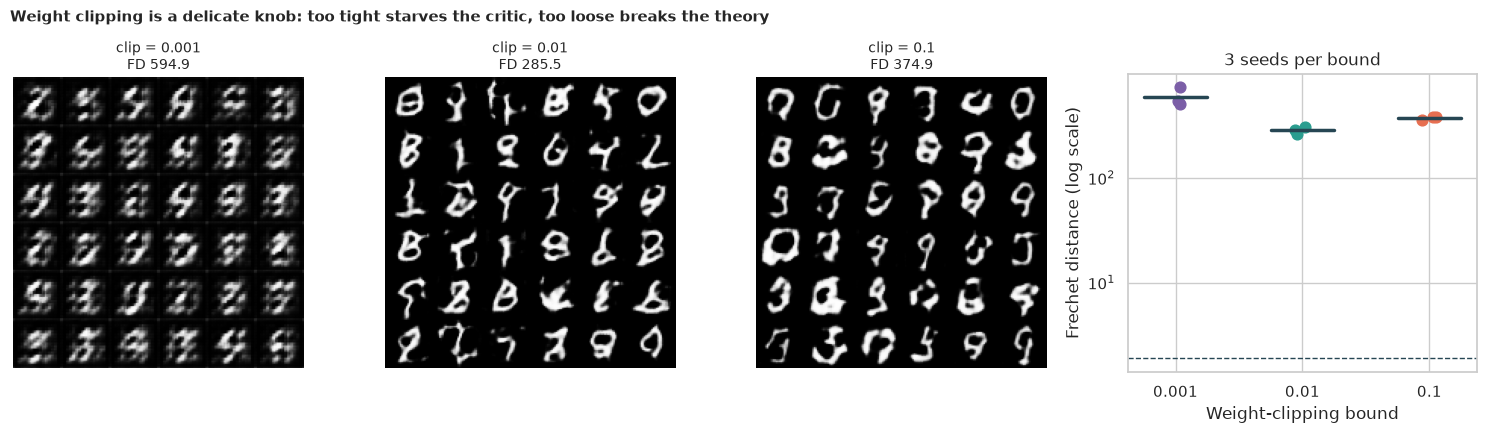

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(15, 4.4), gridspec_kw={"width_ratios": [1, 1, 1, 1.2]})
for ax, clip in zip(axes[:3], CLIPS, strict=True):
    show_grid(clip_gens[clip], ax, n=36)
    mean_fd = clips[clips["clip"] == clip]["fd"].mean()
    ax.set_title(f"clip = {clip}\nFD {mean_fd:.1f}", fontsize=10)
for i, (clip, color) in enumerate(zip(CLIPS, [PURPLE, TEAL, ORANGE], strict=True)):
    sub = clips[clips["clip"] == clip]["fd"]
    axes[3].scatter(
        np.full(len(sub), i) + rng.uniform(-0.07, 0.07, len(sub)), sub, color=color, s=60
    )
    axes[3].plot([i - 0.25, i + 0.25], [sub.mean()] * 2, color=NAVY, lw=2.5)
axes[3].axhline(floor["fd"].mean(), color=NAVY, ls="--", lw=1)
axes[3].set_yscale("log")
axes[3].set_xticks(range(3), [str(c) for c in CLIPS])
axes[3].set_xlabel("Weight-clipping bound")
axes[3].set_ylabel("Frechet distance (log scale)")
axes[3].set_title("3 seeds per bound")
fig.suptitle(
    "Weight clipping is a delicate knob: too tight starves the critic, too loose breaks the theory",
    x=0.01,
    ha="left",
    fontweight="bold",
    fontsize=11,
)
fig.tight_layout()
fig.savefig(OUT_DIR / "02_clipping.png", dpi=150)
plt.show()

**How to read this:**

- **The bound matters a lot:** mean Fréchet distance **594.9** (clip 0.001), **285.5** (clip 0.01) and **374.9** (clip 0.1). Even the best bound is far from the real-digit floor of 1.89. The Kruskal-Wallis test gives **p = 0.027** (with three runs per group). **We reject H₀.**
- **A tight bound strangles the critic:** at clip 0.001, **82.9%** of the critic's weights end up stuck at the bound (78.0% to 86.6%). At 0.01 it is **64.6%** and at 0.1 only **1.6%**. When most weights sit at the bound the critic is a blunt instrument, and the gradients it gives the generator are poor.
- **A loose bound is not safe either:** at clip 0.1 the critic has room, but the critic needs to be a smooth ("1-Lipschitz") function for the Wasserstein estimate to be honest and clipping cannot guarantee that. The FD is **374.9**, worse than 0.01.
- **The sweet spot is narrow and has to be found by trial:** each choice is a factor of ten apart, and the worst is twice as bad as the best.

## 8. H3: does the WGAN beat the classic GAN?

*What:* compare the three WGAN runs (clip 0.01) with the three classic-GAN runs after the same 5,000 generator updates, on all three referee scores, with a Mann-Whitney test on the Fréchet distance. *Why:* the WGAN's selling point is stability and a useful loss. Whether it also gives *better pictures* at this small scale is a separate question.

In [11]:
bce_scores = [judge(gen) for gen, _ in bce_runs]
wgan_scores = [judge(gen) for gen, _, _ in wgan_runs]
head = pd.DataFrame(
    [
        {
            "loss": name,
            "seed": i,
            "fd": s["fd"],
            "is": s["is"],
            "confident": s["confident"],
            "tvd": s["tvd"],
        }
        for name, scores in [("classic GAN (BCE)", bce_scores), ("WGAN (clip 0.01)", wgan_scores)]
        for i, s in enumerate(scores)
    ]
)
print(f"After {GEN_STEPS:,} generator updates (batch {BATCH}):")
print(
    head.groupby("loss")[["fd", "is", "confident", "tvd"]]
    .agg(["mean", "min", "max"])
    .round(2)
    .to_string()
)
a = head[head["loss"].str.startswith("classic")]["fd"].to_numpy()
b = head[head["loss"].str.startswith("WGAN")]["fd"].to_numpy()
mw = stats.mannwhitneyu(b, a)
print(
    f"\nWGAN minus classic GAN, Frechet distance: {b.mean() - a.mean():+.1f}; WGAN better in "
    f"{(b < a.min()).sum()} of {len(b)} runs against the best classic run; "
    f"Mann-Whitney p = {mw.pvalue:.3f} (smallest possible with 3 against 3 is 0.1)"
)

After 5,000 generator updates (batch 64):
                       fd                    is             confident               tvd            
                     mean     min     max  mean   min   max      mean   min   max  mean   min   max
loss                                                                                               
WGAN (clip 0.01)   285.48  262.61  306.44  5.13  4.88  5.36      0.41  0.40  0.42  0.15  0.11  0.19
classic GAN (BCE)  187.78  173.28  198.24  6.43  6.39  6.51      0.57  0.56  0.58  0.09  0.08  0.09

WGAN minus classic GAN, Frechet distance: +97.7; WGAN better in 0 of 3 runs against the best classic run; Mann-Whitney p = 0.100 (smallest possible with 3 against 3 is 0.1)


**How to read this:**

- **The classic GAN wins here:** mean Fréchet distance **187.8** (173.3 to 198.2) against **285.5** for the WGAN (262.6 to 306.4): the WGAN is **97.7 points worse**, and **not one** WGAN run beats even the *best* classic run. The Inception-style score is **6.43 against 5.13** and the referee is confident on **57% against 41%** of images.
- **The significance is capped by the design:** with three runs against three, the smallest p-value the Mann-Whitney test can produce is **0.10**, which is exactly what we get. Read it as "the ranking is perfectly consistent across all 9 pairs", not as a proof.
- **Why?** Plausible reasons (not tested here): weight clipping is a crude constraint and the critic is held back by it (65% of its weights are stuck at the bound); WGAN training is slower per update (small learning rate, RMSprop); and we ran only 5,000 generator updates. The paper's own reason to use WGAN was **stability and a meaningful loss**, not sharper images at a small budget.
- **We do not reject H₀ with confidence,** but we have no support for the idea that the WGAN gives better digits here.

## 9. 🎯 Takeaways

1. **The WGAN's headline claim holds:** the critic's real-minus-fake estimate tracks sample quality very closely (Spearman +0.97 to +0.98 per run), while the classic discriminator loss is a much weaker guide (+0.60 to +0.65).
2. **Weight clipping is touchy:** the Fréchet distance is 595, 285 and 375 for clip 0.001, 0.01 and 0.1 (p = 0.027), and a tight bound leaves 83% of the critic's weights stuck at the bound.
3. **At this budget the classic GAN made better digits:** Fréchet distance 188 against 285, even though the WGAN looked at five times more real digits. Every WGAN run was worse than every classic run (p = 0.10 is the minimum possible with 3 against 3).
4. **A useful loss is not the same as better pictures:** the WGAN's benefit is that you can *see* training progress and compare runs, which the classic loss does not offer.
5. **Always judge a GAN with an independent measure,** not the loss it reports and not a grid of hand-picked samples.

## 10. ⚠️ Limitations

- **The referee is a judge we built.** Its features come from a small classifier, so the Fréchet distance measures similarity *as the referee sees digits* and is not comparable with published FID values.
- **Three seeds per setting**, so rank tests sit at their limits (the smallest possible p-value is 0.10 for 3 against 3).
- **A short run** (5,000 generator updates). The WGAN may still be improving, and a longer run could change the comparison in H3.
- **Different budgets of real data:** the WGAN critic sees 5x more real batches per generator update; we kept the number of *generator* updates equal, the paper's convention.
- **One optimiser setting per recipe;** we did not tune the learning rates, so H3 compares two reasonable recipes and not their best versions.
- **32 x 32 digits, not 64 x 64** as in the legacy scripts; the architecture is a shortened DCGAN.
- **The correlation in H1 is within a run, over time;** the critic's number cannot be compared across clipping bounds or architectures.
- **No human judgement:** the forged digits were never rated by people.